## Problem Statement: Reducing the Operating Cost of an Enterprise AI Assistant

In [1]:
# How can Walmart operate an AI-powered retail assistant that handles thousands of customer questions every day, while reducing its AI operating costs without compromising response accuracy or customer experience?

In [ ]:
# Imagine Walmart has developed an AI-powered Retail Assistant that helps customers with everyday questions, such as:
# - What is the price of Great Value Whole Milk?
# - Which milk is the cheapest?
# - Where can I find a particular product?
# - What is Walmart's return policy?
# - Which detergent should I purchase?
# - What are the store's operating hours?
# Behind the scenes, the assistant uses an LLM, possibly combined with RAG, to retrieve product information and generate answers.

# The assistant works well during testing. However, as Walmart starts receiving 100,000 customer queries per day, a new problem appears.

# Every interaction consumes tokens, and every LLM API call costs money.

# Even when customers ask simple questions, the assistant may repeatedly send lengthy instructions, retrieved documents, and conversation history to an expensive model.

# The challenge is no longer just building a working AI assistant. It is making that assistant economically sustainable at enterprise scale.

# 1. Token Economics
# Measure the tokens consumed by system instructions, retrieved information, customer questions, and AI responses.

# 2. Prompt Compression
# Remove unnecessary words and irrelevant retrieved information without losing important facts.

# 3. Model Routing
# Select an economical model for simple questions and a more capable model for complex questions.

# 4. Response Caching
# Reuse previously generated answers for repeated questions when the information is still valid.

# 5. Batch vs Streaming
# Decide whether to display an answer progressively or return it all at once based on the application.

# 6. Monthly Spend Projection
# Estimate how much Walmart will spend before and after applying different optimisation strategies.

In [3]:
import os, json, time, hashlib
from pathlib import Path
from dotenv import load_dotenv
from openai import OpenAI
import tiktoken

load_dotenv(override=True)
client = OpenAI(api_key=os.getenv('OPENAI_API_KEY'))
print('Client ready.')

Client ready.


## Section 1: Token Economics -- Understanding Cost Drivers

### What is a Token?

A token is the basic unit of text that an LLM processes. Tokens are not words --
they are sub-word units produced by a tokeniser (BPE for GPT models).
On average, 1 token = 0.75 English words, or 4 characters.

**Token count rules of thumb:**

| Content | Approximate tokens |
|---|---|
| 1 English word | 1.3 tokens |
| 1 sentence (15 words) | ~20 tokens |
| 1 paragraph (100 words) | ~130 tokens |
| 1 page (500 words) | ~650 tokens |
| A2A agent system prompt | 200-500 tokens |
| RAG chunk (512 chars) | ~128 tokens |

**Why it matters:** You are charged per token, separately for input and output.
Output tokens cost 2x to 4x more than input tokens depending on the model.

**The four cost drivers in a RAG + Agent pipeline:**

| Driver | Typical share | Optimisation lever |
|---|---|---|
| System prompt | 15-25% | Compress; cache |
| Retrieved context (RAG chunks) | 30-50% | Reduce K; trim chunks |
| Conversation history | 10-30% | Summarise or truncate old turns |
| Output tokens | 10-20% | Set max_tokens; be concise |

**What to remember:**
- Count tokens BEFORE sending a request, not after. Late discovery of token bloat
  means you have already paid for it.
- The system prompt is sent on every single call. A 1,000-token system prompt
  at 100,000 daily queries = 100 million input tokens per day.
- gpt-4o-mini costs roughly 33x less per input token than gpt-4-turbo.
  Not every query needs gpt-4-turbo.

In [4]:
# Token counting with tiktoken

MODEL_PRICING = {
    'gpt-4-turbo':  {'input': 10.00, 'output': 30.00},
    'gpt-4o':       {'input':  5.00, 'output': 15.00},
    'gpt-4o-mini':  {'input':  0.15, 'output':  0.60},
}

def count_tokens(text: str, model: str = 'gpt-4o') -> int:
    """Count tokens in a string using tiktoken."""
    enc = tiktoken.encoding_for_model(model)
    return len(enc.encode(text))

def cost_usd(input_tokens: int, output_tokens: int, model: str) -> float:
    """Compute USD cost for one API call."""
    p = MODEL_PRICING[model]
    return round(
        (input_tokens  / 1_000_000) * p['input'] +
        (output_tokens / 1_000_000) * p['output'],
        6,
    )

# Measure a realistic Walmart Retail Assistant request
SYSTEM_PROMPT = (
    'You are the Walmart Retail Assistant. Help customers with product information, '
    'store policies, price enquiries, and order tracking. '
    'Be concise, accurate, and friendly. '
    'Base your answer only on the provided context. '
    'If the answer is not in the context, say so clearly.'
)

RAG_CONTEXT = (
    'Great Value Whole Milk 1 gallon: price $3.98, Aisle 12, in stock (47 units). '
    'Great Value 2% Milk 1 gallon: price $3.78, Aisle 12, in stock (32 units). '
    'Organic Valley Whole Milk 0.5 gallon: price $5.49, Aisle 14, in stock (12 units). '
    'Walmart store hours: Mon-Sat 6AM-11PM, Sun 7AM-10PM.'
)

USER_QUERY = 'What is the cheapest whole milk option and where can I find it?'

full_prompt = f'Context: {RAG_CONTEXT}\n\nQuestion: {USER_QUERY}'

sys_tokens   = count_tokens(SYSTEM_PROMPT)
ctx_tokens   = count_tokens(RAG_CONTEXT)
query_tokens = count_tokens(USER_QUERY)
total_in     = sys_tokens + ctx_tokens + query_tokens
est_out      = 60  # typical answer length

print('Token breakdown for one Walmart Retail Assistant call:')
print(f'  System prompt  : {sys_tokens:>6} tokens ({sys_tokens/total_in*100:.1f}%)')
print(f'  RAG context    : {ctx_tokens:>6} tokens ({ctx_tokens/total_in*100:.1f}%)')
print(f'  User query     : {query_tokens:>6} tokens ({query_tokens/total_in*100:.1f}%)')
print(f'  Total input    : {total_in:>6} tokens')
print(f'  Est. output    : {est_out:>6} tokens')
print()
print('Cost comparison per call:')
for model in MODEL_PRICING:
    c = cost_usd(total_in, est_out, model)
    daily = round(c * 100_000, 2)
    print(f'  {model:<20} ${c:.6f}  |  @ 100k calls/day: ${daily:.2f}/day')

Token breakdown for one Walmart Retail Assistant call:
  System prompt  :     53 tokens (31.0%)
  RAG context    :    104 tokens (60.8%)
  User query     :     14 tokens (8.2%)
  Total input    :    171 tokens
  Est. output    :     60 tokens

Cost comparison per call:
  gpt-4-turbo          $0.003510  |  @ 100k calls/day: $351.00/day
  gpt-4o               $0.001755  |  @ 100k calls/day: $175.50/day
  gpt-4o-mini          $0.000062  |  @ 100k calls/day: $6.20/day


## Section 2: Prompt Compression

### What is Prompt Compression?

Prompt compression is the practice of reducing the number of input tokens sent to the LLM
while preserving the information needed to produce a correct answer.

**Compression techniques (ranked by implementation effort):**

| Technique | Token reduction | Quality risk | Effort |
|---|---|---|---|
| Remove filler words | 5-10% | Negligible | Low |
| Chunk trimming (cut to K sentences) | 20-40% | Low if K >= 3 | Low |
| Instruction compression | 10-20% | Low | Medium |
| Semantic deduplication | 15-30% | Low | Medium |
| LLMLingua-style compression | 30-60% | Medium | High |

**What to remember:**
- Never compress below the point where the LLM can still answer correctly.
  Always measure faithfulness score before and after compression.
- Compressed prompts must still pass the evaluation gate from Module 4.
- System prompt compression is the highest ROI: same saving multiplied
  across every single API call.

In [5]:
# 1. Remove filler words (5–10% reduction)
# Meaning: Remove unnecessary words without changing the meaning of the sentence.

# Before compression
#     "Could you please kindly help me find out what the current price of Great Value whole milk is?"
# After compression
#     "Find current price of Great Value whole milk."

# The meaning remains the same, but the sentence becomes shorter.
# - Token reduction: 5–10%
# - Quality risk: Negligible
# - Implementation effort: Low

# Production approach: A reusable, concise prompt template maintained in the application or a prompt-management platform such as Langfuse.


# 2. Chunk trimming (20–40% reduction)
# Meaning: When RAG retrieves large documents, keep only the first K sentences of each retrieved chunk.

# For example, suppose Walmart's product database returns this passage:
# Original retrieved chunk — 5 sentences
#     1. Great Value Whole Milk costs $3.98.
#     2. It is available in Aisle 12.
#     3. The package contains one gallon of milk.
#     4. Walmart was established several decades ago.
#     5. Walmart operates numerous stores.

# After trimming to K = 3 sentences
#     1. Great Value Whole Milk costs $3.98.
#     2. It is available in Aisle 12.
#     3. The package contains one gallon of milk.

# We removed the last two sentences because they are not necessary for answering the product question.
# - Token reduction: 20–40%
# - Quality risk: Low if K ≥ 3, according to the notebook
# - Implementation effort: Low

# Important: This technique can lose important information if the relevant answer appears toward the end of the chunk. K = 3 is not a universal guarantee of safety.

# Production approach: Use OpenSearch or Elasticsearch for retrieval, optionally a reranker to identify the most relevant passages, followed by token-budget-aware trimming in LangChain or custom Python code.


# 3. Instruction compression (10–20% reduction)
# Meaning: Shorten the system prompt instructions while retaining the same rules.

# Before compression
#     "You are an intelligent Walmart retail assistant. Your responsibility is to help customers by providing accurate information. Whenever a customer asks about product prices, you should carefully check the available product information and provide the correct price. Please avoid giving information that is not supported by the provided data."

# After compression
#     "You are a Walmart retail assistant. Answer accurately using provided product data. Never invent prices or product information."

# Both prompts communicate essentially the same instructions.
#     - Token reduction: 10–20%
#     - Quality risk: Low
#     - Implementation effort: Medium

# This is especially useful because system prompts may be sent repeatedly with every API request.

# Production approach: Store versioned prompt templates in Langfuse, PromptLayer, or a Git-managed configuration, then evaluate compressed versions against the original using a representative set of customer questions.


# 4. Semantic deduplication (15–30% reduction)
# Meaning: Remove information that has the same meaning, even when written using different words.

# Suppose RAG retrieves three statements:
# Before compression
#     1. Great Value Whole Milk costs $3.98.
#     2. The selling price of Great Value Whole Milk is $3.98.
#     3. Customers can purchase Great Value Whole Milk for $3.98.

# After compression
#     Great Value Whole Milk costs $3.98.

# All three statements convey the same information. We retain just one.
#     - Token reduction: 15–30%
#     - Quality risk: Low
#     - Implementation effort: Medium

# Difference from chunk trimming: Chunk trimming removes sentences based on their position, whereas semantic deduplication removes statements based on meaning.

# Production approach: Use embedding models with a vector-search service such as Databricks Vector Search, OpenSearch, or pgvector to detect semantically similar passages. Deduplicate or group them in the retrieval layer.


# 5. LLMLingua-style compression (30–60% reduction)
# Meaning: Use a more advanced, model-assisted approach to identify which tokens or information are essential and which can potentially be removed.

# Before compression
#     "The Walmart store located in San Jose, California, currently offers Great Value Whole Milk in a one-gallon container for the retail price of $3.98. This item is available for customers to purchase in Aisle 12."

# After compression — illustrative
#     "Walmart San Jose: Great Value Whole Milk, 1 gallon, $3.98, Aisle 12."


# We retain the essential product information while removing most of the surrounding language.

# Unlike basic word removal, LLMLingua-style methods can use a language model to estimate the importance of different parts of a prompt.
#     - Token reduction: 30–60%
#     - Quality risk: Medium
#     - Implementation effort: High
# The example shows the intended effect, rather than the actual output of LLMLingua.

# Production approach: Use LLMLingua or LongLLMLingua-style techniques in a Python inference service, before sending the compressed context to the final answering LLM.

| Technique               | What gets removed?    | Best suited for           |
| ----------------------- | --------------------- | ------------------------- |
| Remove filler words     | Unnecessary words     | Simple prompts            |
| Chunk trimming          | Extra sentences       | RAG documents             |
| Instruction compression | Verbose instructions  | System prompts            |
| Semantic deduplication  | Repeated meaning      | Retrieved context         |
| LLMLingua-style         | Less important tokens | Large prompts and context |

In [6]:
def compress_system_prompt(prompt: str) -> str:
    """Remove filler phrases and compress whitespace."""
    replacements = [
        ('Be concise, accurate, and friendly. ', ''),
        ('Help customers with ', 'Answer queries on '),
        ('Base your answer only on the provided context. ', 'Use only provided context. '),
        ('If the answer is not in the context, say so clearly.', 'Say so if unknown.'),
    ]
    result = prompt
    for old, new in replacements:
        result = result.replace(old, new)
    return ' '.join(result.split())

def compress_context(context: str, max_sentences: int = 4) -> str:
    """Keep only the most relevant sentences by simple sentence truncation."""
    sentences = [s.strip() for s in context.replace('. ', '.|').split('|') if s.strip()] # Product A costs $3.98. Product B costs $3.78. ==> Product A costs $3.98.|Product B costs $3.78.
    return '. '.join(sentences[:max_sentences]) + '.'

compressed_sys  = compress_system_prompt(SYSTEM_PROMPT)
compressed_ctx  = compress_context(RAG_CONTEXT, max_sentences=3)

orig_sys_tok  = count_tokens(SYSTEM_PROMPT)
comp_sys_tok  = count_tokens(compressed_sys)
orig_ctx_tok  = count_tokens(RAG_CONTEXT)
comp_ctx_tok  = count_tokens(compressed_ctx)

print('Prompt Compression Results:')
print(f'  System prompt : {orig_sys_tok} -> {comp_sys_tok} tokens  ({(1-comp_sys_tok/orig_sys_tok)*100:.1f}% reduction)')
print(f'  RAG context   : {orig_ctx_tok} -> {comp_ctx_tok} tokens  ({(1-comp_ctx_tok/orig_ctx_tok)*100:.1f}% reduction)')
print()
new_total_in = comp_sys_tok + comp_ctx_tok + query_tokens
print(f'  Total input before: {total_in} tokens')
print(f'  Total input after : {new_total_in} tokens')
saving_pct = (1 - new_total_in / total_in) * 100
print(f'  Overall reduction : {saving_pct:.1f}%')
print()
for model in MODEL_PRICING:
    c_before = cost_usd(total_in,     est_out, model)
    c_after  = cost_usd(new_total_in, est_out, model)
    daily_saving = round((c_before - c_after) * 100_000, 2)
    print(f'  {model:<20} saving @ 100k/day: ${daily_saving:.2f}/day')

Prompt Compression Results:
  System prompt : 53 -> 33 tokens  (37.7% reduction)
  RAG context   : 104 -> 82 tokens  (21.2% reduction)

  Total input before: 171 tokens
  Total input after : 129 tokens
  Overall reduction : 24.6%

  gpt-4-turbo          saving @ 100k/day: $42.00/day
  gpt-4o               saving @ 100k/day: $21.00/day
  gpt-4o-mini          saving @ 100k/day: $0.70/day


## Section 3: Model Routing

### What is Model Routing?

Model routing is the practice of automatically selecting the cheapest model that can
correctly answer a given query, rather than sending every query to the most powerful
(and most expensive) model.

**Routing decision framework:**

| Query type | Complexity | Recommended model | Rationale |
|---|---|---|---|
| Simple price lookup | Low | gpt-4o-mini | Single-fact retrieval, no reasoning |
| Policy clarification | Medium | gpt-4o-mini | Short context, clear answer |
| Multi-step comparison | High | gpt-4o | Requires reasoning across products |
| Ambiguous / multi-intent | Very high | gpt-4-turbo | Complex planning required |

**Routing signals (features):**
- Query word count (short = simple)
- Number of question marks (multi-intent indicator)
- Presence of comparison words (vs, compare, difference, cheaper)
- Number of retrieved chunks needed
- Previous turn count in conversation

**What to remember:**
- Start with keyword-based routing. It is fast, explainable, and works well
  for structured retail queries.
- Log the routed model and query category for every call. Without this data
  you cannot validate that routing is working correctly.
- Always define a fallback: if the router is uncertain, route to the higher model.
  A wrong answer is more expensive than a higher API cost.

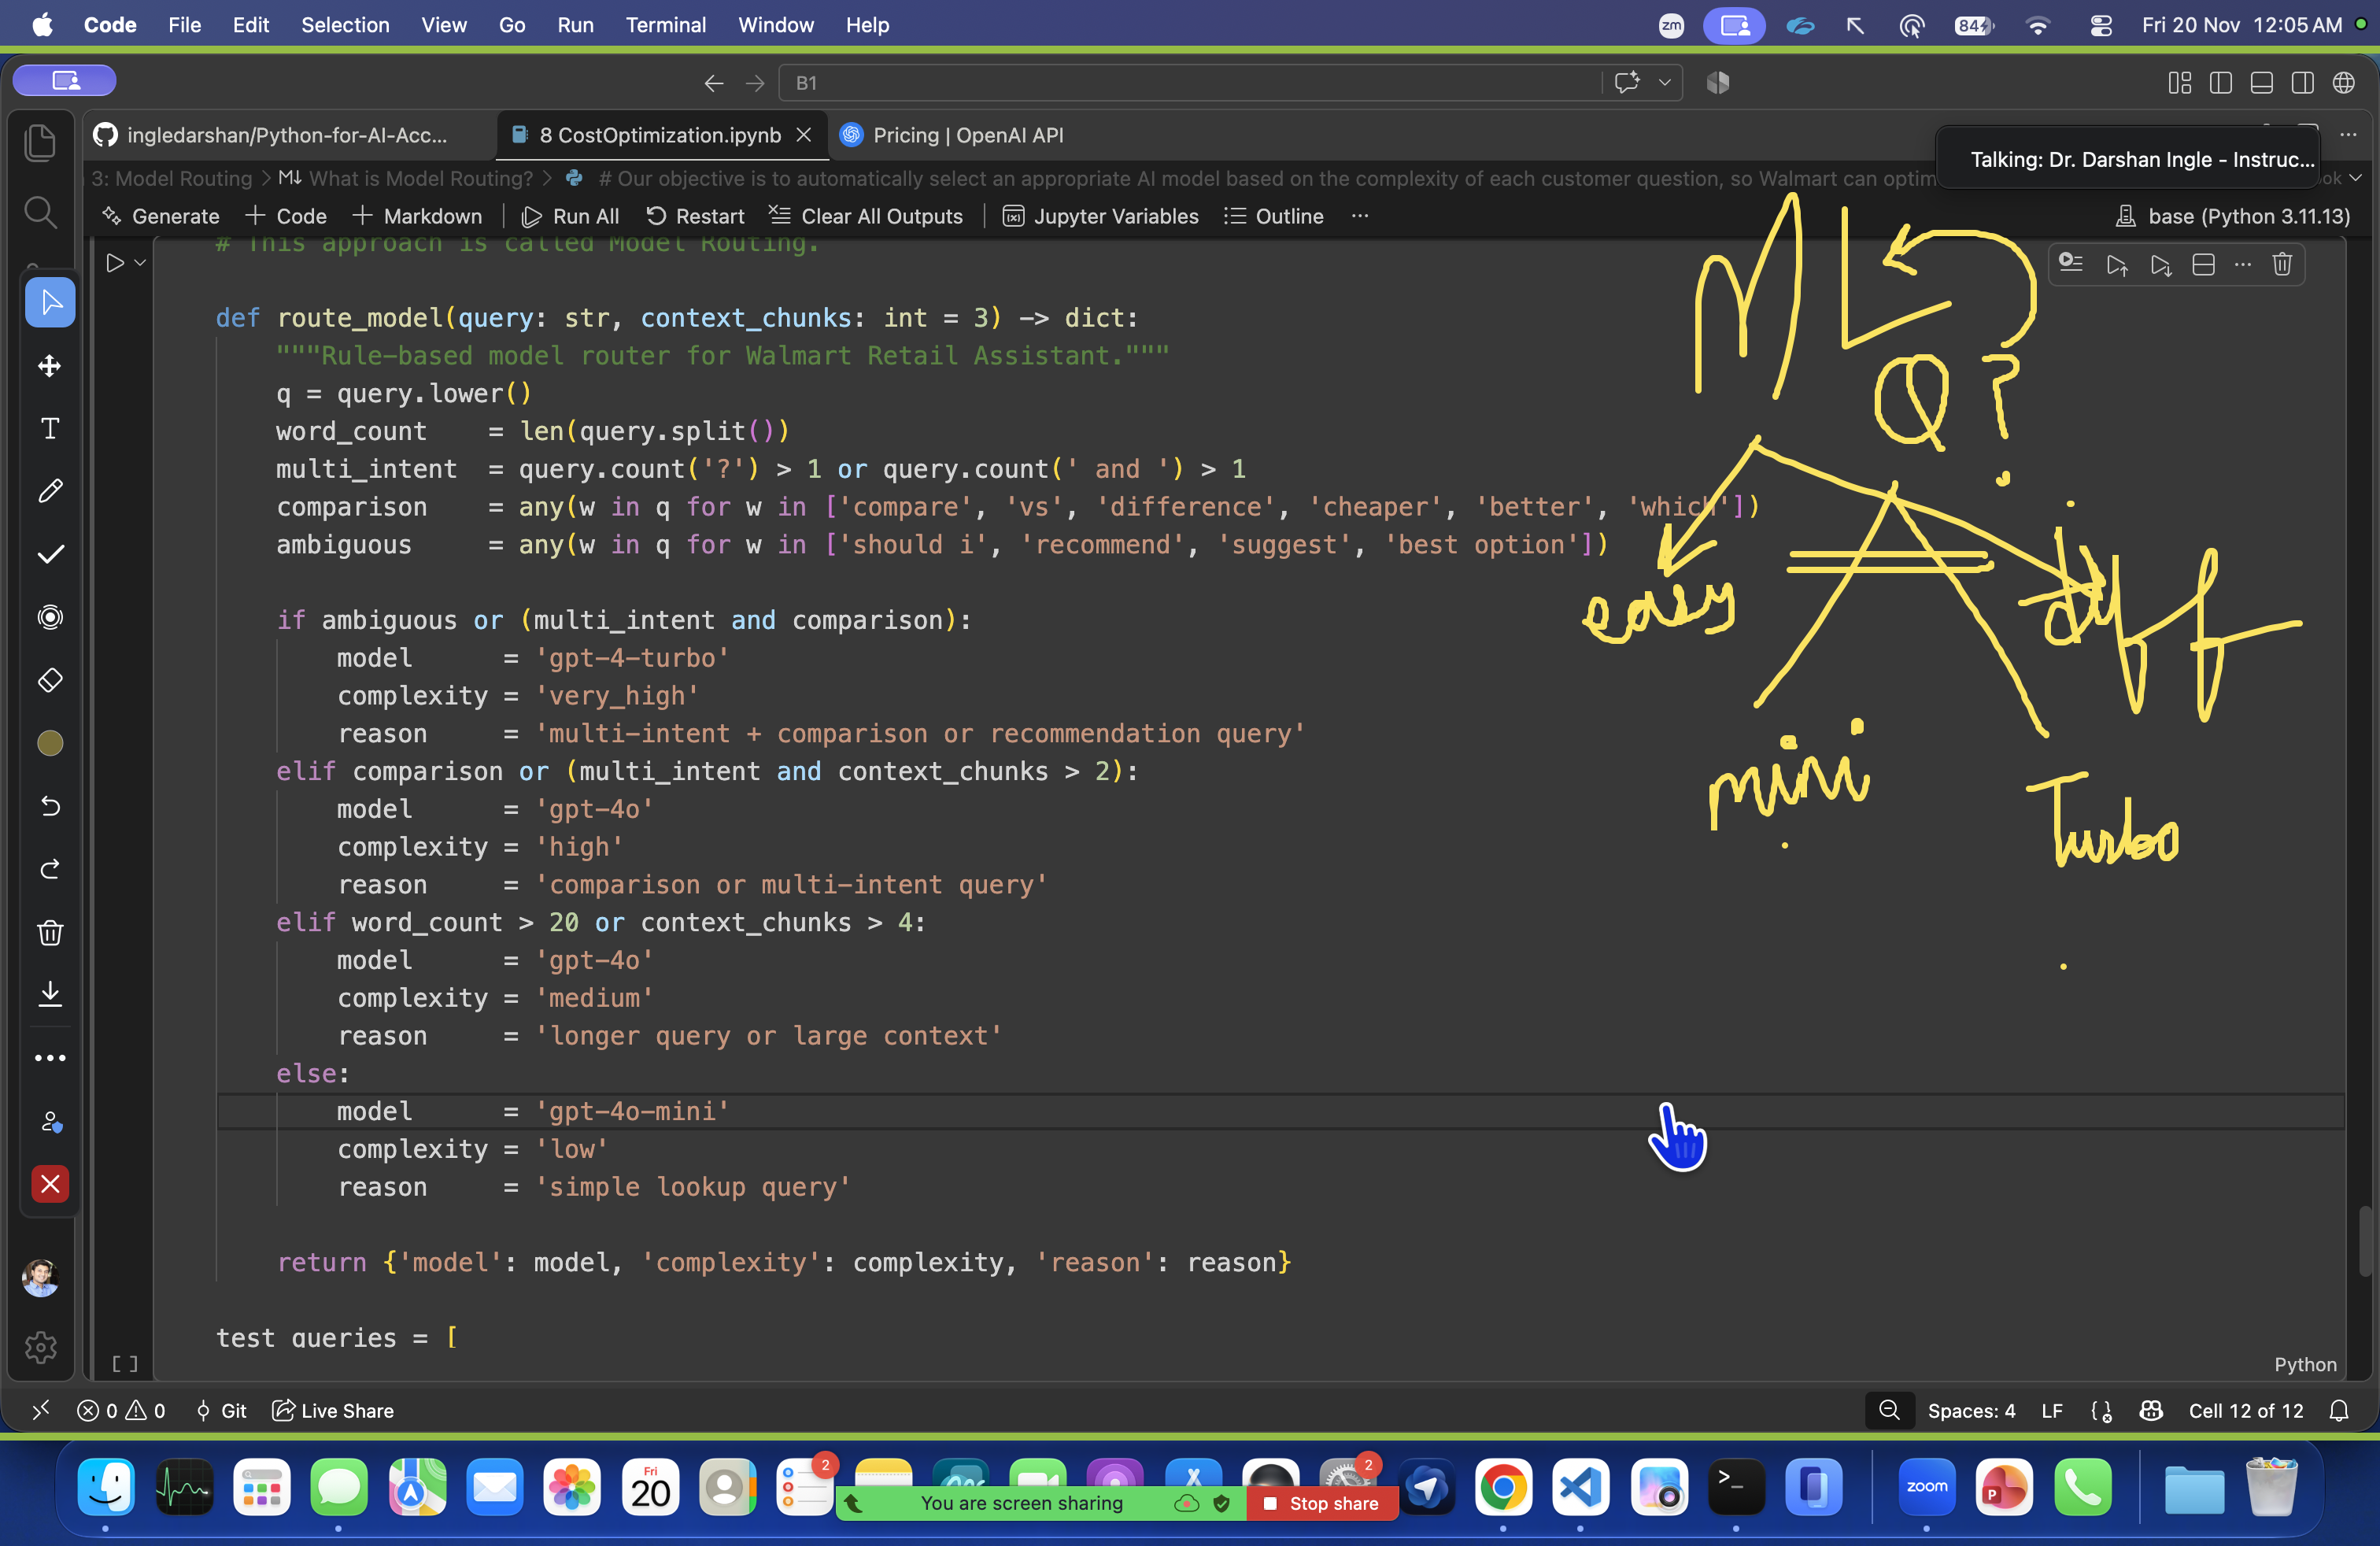

In [7]:
# Prompts:

# Create a data set of 10 rows, having only two columns: the first column will be a customer asking a question to the Walmart HR assistant, which can be a simple straightforward question like, what are the store opening hours, which must be ideally classified as a simple question in the dependent variable, and if someone says compare the price of tight detergent with the ring detergent with respect to quantity, quality, and some other factors, then it should go to the turbo model. So create a data set like that and then write the code to create a machine learning model and save the machine learning model as a pickle file

# I want to code for machine learning, which reads the data and creates a model, then saves the model. print data code in a single cell

# Do not use the pipeline class, do it step-by-step in a standard way

In [8]:
# Our objective is to automatically select an appropriate AI model based on the complexity of each customer question, so Walmart can optimise costs while maintaining response quality.
# This approach is called Model Routing.

def route_model(query: str, context_chunks: int = 3) -> dict:
    """Rule-based model router for Walmart Retail Assistant."""
    q = query.lower()
    word_count    = len(query.split())
    multi_intent  = query.count('?') > 1 or query.count(' and ') > 1 # "What is the price of milk? Is it available? Which aisle is it in?".
    # "Which milk should I buy for a toddler and is it in stock?"
    comparison    = any(w in q for w in ['compare', 'vs', 'difference', 'cheaper', 'better', 'which'])
    ambiguous     = any(w in q for w in ['should i', 'recommend', 'suggest', 'best option'])

    if ambiguous or (multi_intent and comparison):
        model      = 'gpt-4-turbo'
        complexity = 'very_high'
        reason     = 'multi-intent + comparison or recommendation query'
    elif comparison or (multi_intent and context_chunks > 2):
        model      = 'gpt-4o'
        complexity = 'high'
        reason     = 'comparison or multi-intent query'
    elif word_count > 20 or context_chunks > 4:
        model      = 'gpt-4o'
        complexity = 'medium'
        reason     = 'longer query or large context'
    else:
        model      = 'gpt-4o-mini'
        complexity = 'low'
        reason     = 'simple lookup query'

    return {'model': model, 'complexity': complexity, 'reason': reason}

test_queries = [
    ('What is the price of Great Value Milk?',                      1),
    ('What is the return policy for electronics?',                   2),
    ('Compare Great Value and Tide detergent on price and value.',   3),
    ('Which milk should I buy for a toddler and is it in stock?',    3),
    ('Recommend the best budget laundry detergent for a family.',    4),
]

print('Model Routing Decisions:')
print(f'{"Query":<55} {"Model":<15} {"Complexity"}')
print('-' * 90)
for query, chunks in test_queries:
    r = route_model(query, chunks)
    print(f'{query[:54]:<55} {r["model"]:<15} {r["complexity"]}')
    print(f'  Reason: {r["reason"]}')
    print()

Model Routing Decisions:
Query                                                   Model           Complexity
------------------------------------------------------------------------------------------
What is the price of Great Value Milk?                  gpt-4o-mini     low
  Reason: simple lookup query

What is the return policy for electronics?              gpt-4o-mini     low
  Reason: simple lookup query

Compare Great Value and Tide detergent on price and va  gpt-4-turbo     very_high
  Reason: multi-intent + comparison or recommendation query

Which milk should I buy for a toddler and is it in sto  gpt-4-turbo     very_high
  Reason: multi-intent + comparison or recommendation query

Recommend the best budget laundry detergent for a fami  gpt-4-turbo     very_high
  Reason: multi-intent + comparison or recommendation query



## Section 4: Response Caching

### What is Response Caching?

Response caching stores the output of an LLM call and returns the stored result
for subsequent identical (or near-identical) requests, bypassing the API entirely.

**Cache hit rate formula:**
```
Cache hit rate = cached_responses_served / total_requests
Cost savings   = hit_rate * avg_cost_per_call * daily_volume
```

**Cache strategies:**

| Strategy | How it works | Hit rate | Risk |
|---|---|---|---|
| Exact match | Hash query + context | Low (3-8%) | None |
| Normalised match | Lowercase, strip punctuation, then hash | Medium (10-20%) | None |
| Semantic cache | Embed query, find nearest cached query | High (25-40%) | Stale answers |

**Cache invalidation rules for Walmart Retail Assistant:**
- Price data: TTL = 1 hour (prices change frequently)
- Inventory data: TTL = 15 minutes
- Store hours: TTL = 24 hours
- Return policies: TTL = 7 days

**What to remember:**
- Never cache personalised responses (order status, account queries).
- Log every cache hit and miss. A hit rate below 5% means the cache is not worth
  the operational complexity.
- Always include the cache key components in your structured logs.

In [9]:
import time as _time

class ResponseCache:
    """Simple in-memory cache with TTL for Walmart Retail Assistant responses."""

    def __init__(self):
        self._store: dict = {}
        self.hits   = 0
        self.misses = 0

    def _key(self, query: str, context: str) -> str:
        normalised = ' '.join(query.lower().strip().split())
        return hashlib.sha256(f'{normalised}|{context}'.encode()).hexdigest()[:16]

    def get(self, query: str, context: str) -> str | None:
        k = self._key(query, context)
        entry = self._store.get(k)
        if entry and _time.time() < entry['expires']:
            self.hits += 1
            return entry['answer']
        self.misses += 1
        return None

    def set(self, query: str, context: str, answer: str, ttl_seconds: int = 3600):
        k = self._key(query, context)
        self._store[k] = {'answer': answer, 'expires': _time.time() + ttl_seconds}

    @property
    def hit_rate(self) -> float:
        total = self.hits + self.misses
        return round(self.hits / total, 3) if total > 0 else 0.0

    @property
    def size(self) -> int:
        return len(self._store)


def cached_call(query: str, context: str, model: str, cache: ResponseCache) -> dict:
    """Make an LLM call with cache lookup."""
    cached = cache.get(query, context)
    if cached:
        return {'answer': cached, 'source': 'cache', 'cost_usd': 0.0}

    resp = client.chat.completions.create(
        model=model,
        messages=[
            {'role': 'system', 'content': 'You are the Walmart Retail Assistant. Answer using only the provided context.'},
            {'role': 'user',   'content': f'Context: {context}\n\nQuestion: {query}'},
        ],
        temperature=0,
        max_tokens=120,
    )
    answer = resp.choices[0].message.content
    c = cost_usd(resp.usage.prompt_tokens, resp.usage.completion_tokens, model)
    cache.set(query, context, answer, ttl_seconds=3600)
    return {'answer': answer, 'source': 'api', 'cost_usd': c}

cache = ResponseCache()
ctx   = 'Great Value Whole Milk 1 gallon: price $3.98, Aisle 12. Store hours: Mon-Sat 6AM-11PM.'
queries = [
    'What is the price of Great Value Whole Milk?',
    'Where can I find Great Value Whole Milk?',
    'What is the price of Great Value Whole Milk?',  # repeat -- should hit cache
    'What are the store hours?',
    'What are the store hours?',                     # repeat -- should hit cache
]

total_cost = 0.0
print('Cached call results:')
for q in queries:
    routed = route_model(q)
    result = cached_call(q, ctx, routed['model'], cache)
    total_cost += result['cost_usd']
    print(f'  [{result["source"].upper():<5}] {q[:55]}')
    print(f'         Model: {routed["model"]} | Cost: ${result["cost_usd"]:.6f}')

print(f'\nCache hit rate: {cache.hit_rate:.1%}')
print(f'Total cost    : ${total_cost:.6f}')

Cached call results:
  [API  ] What is the price of Great Value Whole Milk?
         Model: gpt-4o-mini | Cost: $0.000019
  [API  ] Where can I find Great Value Whole Milk?
         Model: gpt-4o-mini | Cost: $0.000019
  [CACHE] What is the price of Great Value Whole Milk?
         Model: gpt-4o-mini | Cost: $0.000000
  [API  ] What are the store hours?
         Model: gpt-4o-mini | Cost: $0.000019
  [CACHE] What are the store hours?
         Model: gpt-4o-mini | Cost: $0.000000

Cache hit rate: 40.0%
Total cost    : $0.000057


## Section 5: Batch vs Streaming

### What is the Batch vs Streaming Trade-off?

**Streaming** sends tokens to the client as they are generated, giving the user
a response that appears word by word. This reduces perceived latency significantly
even when total generation time is the same.

**Batch** waits for the complete response before returning anything.
It is simpler to implement, easier to post-process, and easier to cache.

| Dimension | Streaming | Batch |
|---|---|---|
| Time to first token | Low (ms) | High (seconds) |
| Total generation time | Same | Same |
| Implementation complexity | Higher | Lower |
| Post-processing | Harder (partial text) | Easier |
| Caching | Hard (stream is stateful) | Easy |
| Cost | Same | Same |
| Best for | Chat interfaces, long answers | Evaluation, batch jobs, caching |

**Walmart Retail Assistant decision:**
- Customer-facing chat: use streaming (perceived latency matters)
- Evaluation pipelines (IN10, IN11): use batch (easier to process and cache)
- Nightly batch jobs (reindexing, report generation): use batch

**What to remember:**
- Streaming does NOT reduce token cost. You pay for the same tokens either way.
- Streaming makes it harder to implement response caching -- you must buffer
  the full stream before caching it.
- Never stream to a downstream system that expects a complete JSON object.

## Section 6: Monthly Spend Projection

### Why Project Monthly Spend?

A monthly spend projection converts per-call token costs into a number that
business stakeholders and FinOps teams can budget against.
It also reveals the ROI of each optimisation technique in dollar terms.

**Projection formula:**
```
monthly_cost = daily_calls * avg_cost_per_call * 30
optimised_monthly = monthly_cost * (1 - cache_hit_rate) * (1 - compression_saving)
```

In [10]:
def monthly_projection(
    daily_calls: int,
    avg_input_tokens: int,
    avg_output_tokens: int,
    model_mix: dict,
    cache_hit_rate: float = 0.0,
    compression_saving: float = 0.0,
) -> dict:
    """Project monthly spend with and without optimisations."""
    effective_calls = daily_calls * (1 - cache_hit_rate)
    eff_input       = int(avg_input_tokens  * (1 - compression_saving))
    eff_output      = avg_output_tokens

    daily_cost = 0.0
    for model, share in model_mix.items():
        calls_this_model = effective_calls * share
        daily_cost += calls_this_model * cost_usd(eff_input, eff_output, model)

    return {
        'daily_calls':        daily_calls,
        'cache_hit_rate':     cache_hit_rate,
        'compression_saving': compression_saving,
        'effective_calls':    int(effective_calls),
        'daily_cost_usd':     round(daily_cost, 2),
        'monthly_cost_usd':   round(daily_cost * 30, 2),
        'annual_cost_usd':    round(daily_cost * 365, 2),
    }

# Scenario 1: No optimisation, all gpt-4-turbo
s1 = monthly_projection(
    daily_calls=100_000,
    avg_input_tokens=600,
    avg_output_tokens=80,
    model_mix={'gpt-4-turbo': 1.0},
)

# Scenario 2: Model routing (70% mini, 20% 4o, 10% 4-turbo) + 20% compression
s2 = monthly_projection(
    daily_calls=100_000,
    avg_input_tokens=600,
    avg_output_tokens=80,
    model_mix={'gpt-4o-mini': 0.70, 'gpt-4o': 0.20, 'gpt-4-turbo': 0.10},
    compression_saving=0.20,
)

# Scenario 3: Scenario 2 + 25% cache hit rate
s3 = monthly_projection(
    daily_calls=100_000,
    avg_input_tokens=600,
    avg_output_tokens=80,
    model_mix={'gpt-4o-mini': 0.70, 'gpt-4o': 0.20, 'gpt-4-turbo': 0.10},
    compression_saving=0.20,
    cache_hit_rate=0.25,
)

print('Monthly Spend Projection (100,000 calls/day):')
print()
print(f'{"Scenario":<45} {"Monthly ($)":<14} {"Annual ($)":<12} Saving vs S1')
print('-' * 80)
scenarios = [
    ('S1: All gpt-4-turbo, no optimisation',    s1),
    ('S2: Model routing + 20% compression',      s2),
    ('S3: S2 + 25% cache hit rate',              s3),
]
for label, s in scenarios:
    saving = round((1 - s['monthly_cost_usd'] / s1['monthly_cost_usd']) * 100, 1) if s1['monthly_cost_usd'] > 0 else 0
    flag   = f'-{saving}%' if saving > 0 else '-'
    print(f'{label:<45} ${s["monthly_cost_usd"]:>10,.2f}   ${s["annual_cost_usd"]:>10,.2f}   {flag}')

print()
print(f'Combined optimisation saves {round((1-s3["monthly_cost_usd"]/s1["monthly_cost_usd"])*100,1)}% of monthly token cost.')

Monthly Spend Projection (100,000 calls/day):

Scenario                                      Monthly ($)    Annual ($)   Saving vs S1
--------------------------------------------------------------------------------
S1: All gpt-4-turbo, no optimisation          $ 25,200.00   $306,600.00   -
S2: Model routing + 20% compression           $  4,572.00   $ 55,626.00   -81.9%
S3: S2 + 25% cache hit rate                   $  3,429.00   $ 41,719.50   -86.4%

Combined optimisation saves 86.4% of monthly token cost.


## Summary

| Technique | Typical saving | Implementation effort |
|---|---|---|
| Prompt compression | 15-30% token reduction | Low |
| Model routing | 60-80% cost reduction | Medium |
| Response caching | 20-40% call reduction | Medium |
| Batch vs streaming | No cost saving -- latency perception trade-off | Low |

**Combined:** Model routing + compression + caching can reduce monthly spend
by 70-85% compared to an unoptimised all-gpt-4-turbo deployment.